In [1]:
import os
import torch
import torch.nn as nn
from torch import optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import save_image
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
print("GPU Name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

transform = transforms.Compose([
    transforms.Resize(64),
    transforms.CenterCrop(64),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

dataset_path = "/kaggle/input/datasets/soumikrakshit/anime-faces"
dataset = datasets.ImageFolder(root=dataset_path, transform=transform)
dataloader = DataLoader(dataset, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)

print("Total images:", len(dataset))
print("Number of batches:", len(dataloader))

Using device: cuda
GPU Name: Tesla T4
Total images: 43102
Number of batches: 337


In [2]:
# ---------- Generator ----------
class Generator(nn.Module):
    def __init__(self, nz=100, ngf=64, nc=3):
        super(Generator, self).__init__()
        self.main = nn.Sequential(
            nn.ConvTranspose2d(nz, ngf * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(ngf * 8),
            nn.ReLU(True),
            nn.ConvTranspose2d(ngf * 8, ngf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(True),
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(True),
            nn.ConvTranspose2d(ngf * 2, ngf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf),
            nn.ReLU(True),
            nn.ConvTranspose2d(ngf, nc, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, input):
        return self.main(input)


# ---------- Discriminator ----------
class Discriminator(nn.Module):
    def __init__(self, nc=3, ndf=64):
        super(Discriminator, self).__init__()
        self.main = nn.Sequential(
            nn.Conv2d(nc, ndf, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 4),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf * 4, ndf * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 8),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf * 8, 1, 4, 1, 0, bias=False),
            nn.Sigmoid()
        )

    def forward(self, input):
        return self.main(input).view(-1, 1).squeeze(1)


nz = 100
netG = Generator(nz=nz).to(device)
netD = Discriminator().to(device)

print("Generator and Discriminator created successfully!")

Generator and Discriminator created successfully!


In [3]:
criterion = nn.BCELoss()
optimizerD = optim.Adam(netD.parameters(), lr=0.0002, betas=(0.5, 0.999))
optimizerG = optim.Adam(netG.parameters(), lr=0.0002, betas=(0.5, 0.999))

fixed_noise = torch.randn(64, nz, 1, 1, device=device)

num_epochs = 25
print("Training setup done! Epochs:", num_epochs)

Training setup done! Epochs: 25


In [4]:
print("Starting Training...")

for epoch in range(num_epochs):
    for i, (real_images, _) in enumerate(tqdm(dataloader, desc=f"Epoch {epoch+1}/{num_epochs}")):
        real_images = real_images.to(device)
        batch_size = real_images.size(0)

        # ---------------------
        # Train Discriminator
        # ---------------------
        netD.zero_grad()
        
        label_real = torch.full((batch_size,), 1.0, dtype=torch.float, device=device)
        output = netD(real_images)
        errD_real = criterion(output, label_real)
        errD_real.backward()

        noise = torch.randn(batch_size, nz, 1, 1, device=device)
        fake = netG(noise)
        label_fake = torch.full((batch_size,), 0.0, dtype=torch.float, device=device)
        output = netD(fake.detach())
        errD_fake = criterion(output, label_fake)
        errD_fake.backward()
        
        errD = errD_real + errD_fake
        optimizerD.step()

        # ---------------------
        # Train Generator
        # ---------------------
        netG.zero_grad()
        label_real = torch.full((batch_size,), 1.0, dtype=torch.float, device=device)
        output = netD(fake)
        errG = criterion(output, label_real)
        errG.backward()
        optimizerG.step()

    # Save generated images every epoch
    with torch.no_grad():
        fake = netG(fixed_noise).detach().cpu()
    save_image(fake, f"dcgan_epoch_{epoch+1:02d}.png", normalize=True, nrow=8)
    
    print(f"Epoch [{epoch+1}/{num_epochs}]  Loss_D: {errD.item():.4f}  Loss_G: {errG.item():.4f}")

print("Training Finished!")

Starting Training...


Epoch 1/25:   0%|          | 0/337 [00:00<?, ?it/s]

Epoch [1/25]  Loss_D: 0.5930  Loss_G: 3.2400


Epoch 2/25:   0%|          | 0/337 [00:00<?, ?it/s]

Epoch [2/25]  Loss_D: 0.2485  Loss_G: 5.8798


...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f6f81ca1080>Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7f6f81ca1080>Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
        self._shutdown_workers()self._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():    
if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
      File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
assert self._parent_pid == os.getpid(), 'can only test a

Epoch [24/25]  Loss_D: 0.5041  Loss_G: 7.9607


Epoch 25/25:   0%|          | 0/337 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f6f81ca1080>
Exception ignored in: Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
<function _MultiProcessingDataLoaderIter.__del__ at 0x7f6f81ca1080>    
self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    if w.is_alive():
      File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
self._shutdown_workers()    
assert self._parent_pid == os.getpid(), 'can only test a child process'  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

AssertionError    : if w.is_alive():can only test a child process
  File "/usr/lib/p

Epoch [25/25]  Loss_D: 0.8225  Loss_G: 10.8698
Training Finished!


In [5]:
import matplotlib.pyplot as plt
from PIL import Image
import glob

image_files = sorted(glob.glob("dcgan_epoch_*.png"))
print("Total saved images:", len(image_files))
print(image_files[-5:])   # last 5 files

Total saved images: 25
['dcgan_epoch_21.png', 'dcgan_epoch_22.png', 'dcgan_epoch_23.png', 'dcgan_epoch_24.png', 'dcgan_epoch_25.png']


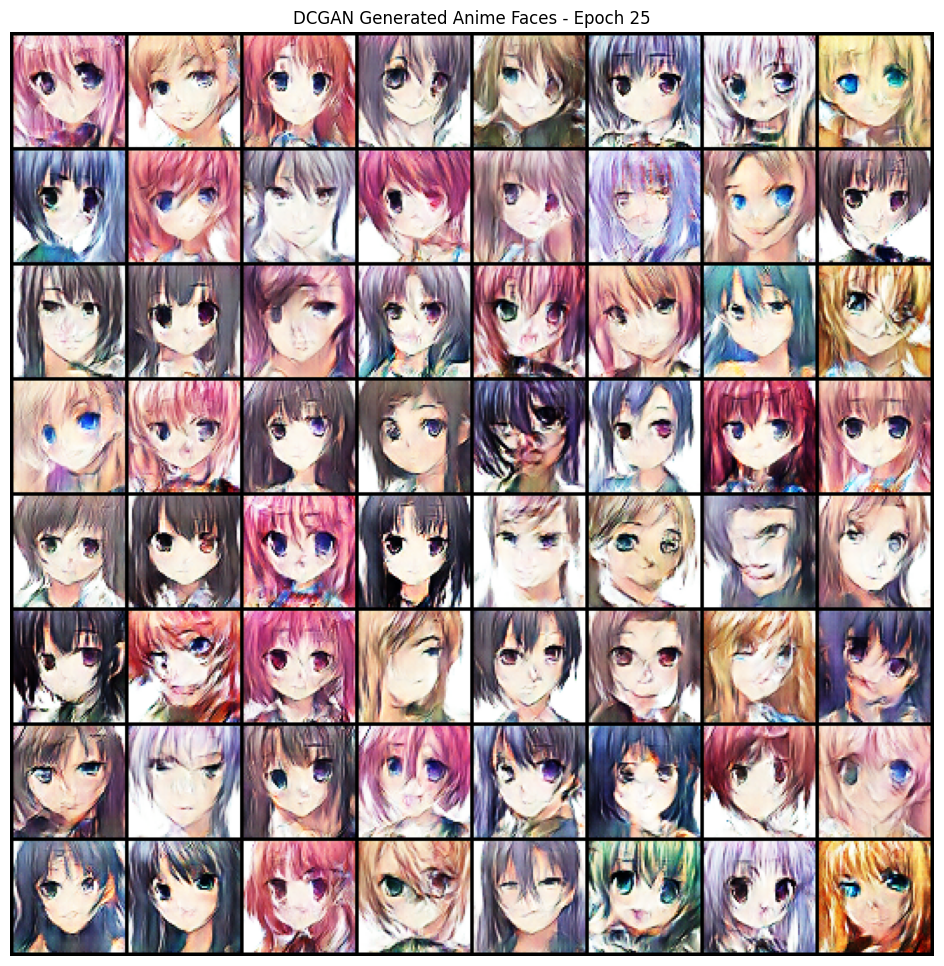

In [6]:
img = Image.open("dcgan_epoch_25.png")
plt.figure(figsize=(12, 12))
plt.imshow(img)
plt.axis("off")
plt.title("DCGAN Generated Anime Faces - Epoch 25")
plt.show()

In [7]:
extra_epochs = 15
print("Starting extra training...")

for epoch in range(num_epochs, num_epochs + extra_epochs):
    for i, (real_images, _) in enumerate(tqdm(dataloader, desc=f"Epoch {epoch+1}")):
        real_images = real_images.to(device)
        batch_size = real_images.size(0)

        # Train Discriminator
        netD.zero_grad()
        label_real = torch.full((batch_size,), 1.0, dtype=torch.float, device=device)
        output = netD(real_images)
        errD_real = criterion(output, label_real)
        errD_real.backward()

        noise = torch.randn(batch_size, nz, 1, 1, device=device)
        fake = netG(noise)
        label_fake = torch.full((batch_size,), 0.0, dtype=torch.float, device=device)
        output = netD(fake.detach())
        errD_fake = criterion(output, label_fake)
        errD_fake.backward()
        errD = errD_real + errD_fake
        optimizerD.step()

        # Train Generator
        netG.zero_grad()
        label_real = torch.full((batch_size,), 1.0, dtype=torch.float, device=device)
        output = netD(fake)
        errG = criterion(output, label_real)
        errG.backward()
        optimizerG.step()

    # Save image
    with torch.no_grad():
        fake = netG(fixed_noise).detach().cpu()
    save_image(fake, f"dcgan_epoch_{epoch+1:02d}.png", normalize=True, nrow=8)
    
    print(f"Epoch [{epoch+1}]  Loss_D: {errD.item():.4f}  Loss_G: {errG.item():.4f}")

print("Extra training finished!")

Starting extra training...


Epoch 26:   0%|          | 0/337 [00:00<?, ?it/s]

Epoch [26]  Loss_D: 0.2622  Loss_G: 5.9976


Epoch 27:   0%|          | 0/337 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f6f81ca1080>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f6f81ca1080>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

...

Epoch 39:   0%|          | 0/337 [00:00<?, ?it/s]

Epoch [39]  Loss_D: 0.1488  Loss_G: 4.5371


Epoch 40:   0%|          | 0/337 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f6f81ca1080>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: Exception ignored in: can only test a child process
<function _MultiProcessingDataLoaderIter.__del__ at 0x7f6f81ca1080>
Traceback (most recent call last):
Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
<function _MultiProcessingDataLoaderIter.__del__ at 0x7f6f81ca1080>
    Traceback (most recent call last):
self._shutdown_workers()  File "/usr/local/lib/pyth

Epoch [40]  Loss_D: 0.0629  Loss_G: 4.6222
Extra training finished!


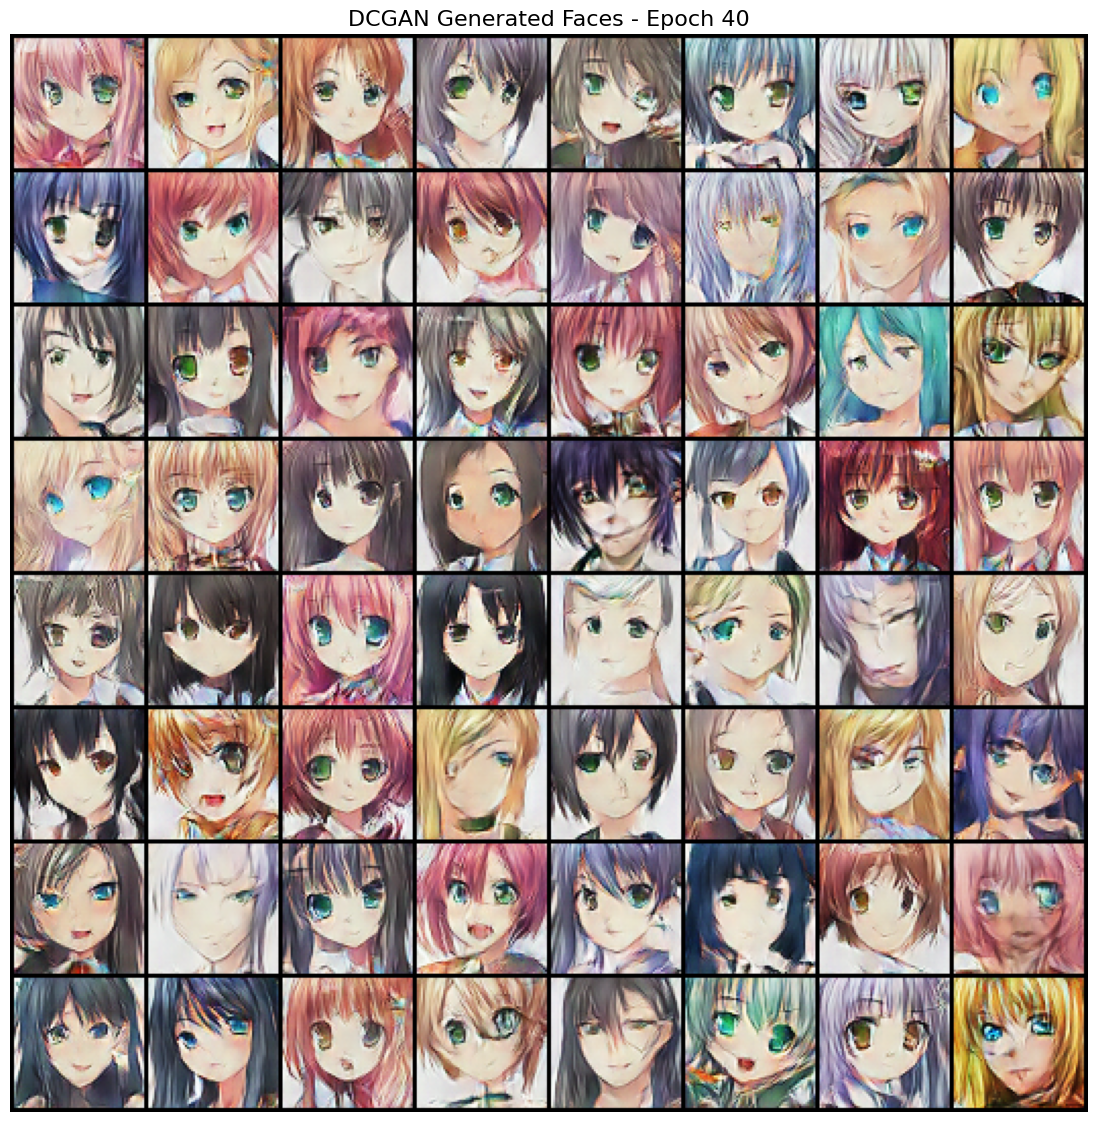

In [8]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open("dcgan_epoch_40.png")

plt.figure(figsize=(14, 14))
plt.imshow(img)
plt.axis("off")
plt.title("DCGAN Generated Faces - Epoch 40", fontsize=16)
plt.show()

In [9]:
torch.save(netG.state_dict(), "dcgan_generator.pth")
torch.save(netD.state_dict(), "dcgan_discriminator.pth")
print("Models saved successfully!")

Models saved successfully!


In [10]:
netG.eval()
with torch.no_grad():
    noise = torch.randn(64, 100, 1, 1, device=device)
    fake = netG(noise).cpu()

save_image(fake, "final_anime_faces.png", normalize=True, nrow=8)
print("Final images saved as final_anime_faces.png")

Final images saved as final_anime_faces.png


In [11]:
import os
print("Saved files:")
print(os.listdir("/kaggle/working"))

Saved files:
['dcgan_epoch_19.png', 'dcgan_epoch_13.png', 'dcgan_epoch_16.png', 'dcgan_epoch_31.png', '__notebook__.ipynb', 'dcgan_epoch_27.png', 'dcgan_epoch_22.png', 'dcgan_epoch_34.png', 'dcgan_epoch_05.png', 'dcgan_epoch_10.png', 'dcgan_epoch_18.png', 'dcgan_generator.pth', 'dcgan_epoch_21.png', 'dcgan_epoch_15.png', 'dcgan_epoch_37.png', 'dcgan_epoch_25.png', 'dcgan_epoch_04.png', 'dcgan_epoch_28.png', 'dcgan_epoch_01.png', 'dcgan_epoch_14.png', 'dcgan_discriminator.pth', 'dcgan_epoch_11.png', 'dcgan_epoch_35.png', 'dcgan_epoch_26.png', 'dcgan_epoch_38.png', 'dcgan_epoch_23.png', 'dcgan_epoch_40.png', 'dcgan_epoch_30.png', 'dcgan_epoch_29.png', 'dcgan_epoch_09.png', 'dcgan_epoch_24.png', 'dcgan_epoch_03.png', 'dcgan_epoch_20.png', 'dcgan_epoch_17.png', 'dcgan_epoch_12.png', 'dcgan_epoch_06.png', 'dcgan_epoch_33.png', 'dcgan_epoch_02.png', 'dcgan_epoch_36.png', 'dcgan_epoch_07.png', 'dcgan_epoch_08.png', 'final_anime_faces.png', 'dcgan_epoch_32.png', 'dcgan_epoch_39.png']
